In [59]:
import os
import sys
import numpy as np

project_root = os.path.abspath("..")
sys.path.insert(0, project_root)


# Health Data Analysis

## 1. Data import
Här förbereds projektet genom att nödvändiga bibliotek importeras
och hälsodatan läses in för vidare analys

In [60]:
import pandas as pd
from src.data_loader import load_data

df = load_data()

## 2. Data Overview
I det här avsnittet undersöks datasetets struktur och innehåll.
Vi tittar bland annat på antalet observationer, tillgängliga variabler och hur datan är uppbyggd

In [61]:
df.head()


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease
0,1,57,F,168.9,65.8,141.8,4.58,No,0
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0
2,3,59,F,169.9,82.2,151.7,6.16,No,0
3,4,72,M,157.7,93.1,151.0,6.63,No,0
4,5,46,M,192.6,104.1,144.1,5.21,No,0


In [62]:
df.shape

(800, 9)

In [63]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           800 non-null    int64  
 1   age          800 non-null    int64  
 2   sex          800 non-null    str    
 3   height       800 non-null    float64
 4   weight       800 non-null    float64
 5   systolic_bp  800 non-null    float64
 6   cholesterol  800 non-null    float64
 7   smoker       800 non-null    str    
 8   disease      800 non-null    int64  
dtypes: float64(4), int64(3), str(2)
memory usage: 56.4 KB


In [64]:
df.describe()


,id,age,height,weight,systolic_bp,cholesterol,disease
count,800.0000,800.000000,800.000000,800.000000,800.000000,800.000000,800.000000
mean,400.5000,49.426250,171.849250,73.413000,149.178625,4.929150,0.058750
std,231.0844,14.501118,9.804259,13.685059,12.793360,0.848413,0.235303
min,1.0000,18.000000,144.400000,33.700000,106.800000,2.500000,0.000000
25%,200.7500,39.000000,164.775000,64.800000,140.900000,4.327500,0.000000
50%,400.5000,50.000000,171.350000,73.200000,149.400000,4.970000,0.000000
75%,600.2500,59.000000,178.925000,82.600000,157.600000,5.482500,0.000000
max,800.0000,90.000000,200.400000,114.400000,185.900000,7.880000,1.000000


In [65]:
df.isnull().sum()

id             0
age            0
sex            0
height         0
weight         0
systolic_bp    0
cholesterol    0
smoker         0
disease        0
dtype: int64

In [66]:
df.duplicated().sum()

np.int64(0)

## Data Overview Summary

Datasetet innehåller 800 observationer och 9 variabler

Det finns inga saknade värden i datasetet

Inga duplicerade rader har upptäckts

Samtilga kolumner innehåller 800 giltliga värden

## 3. exploratory Data Analysis
I det här avsnittet undersöks datasetets innehåll mer ingående.
Genom diagram och statistiska sammanställningar letar vi efter
mönster och fördelningar i de olika hälsovariablerna

3.1, Ålders fördelningen

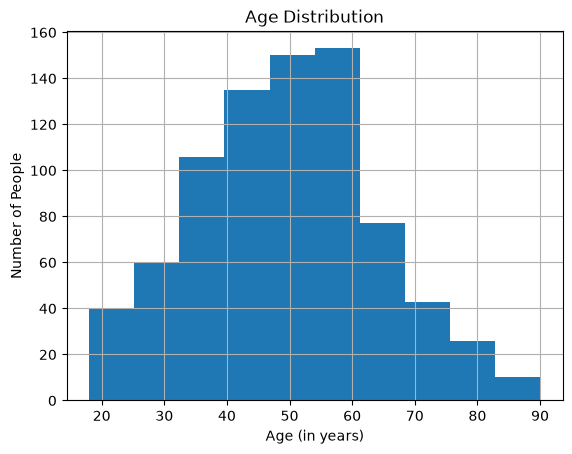

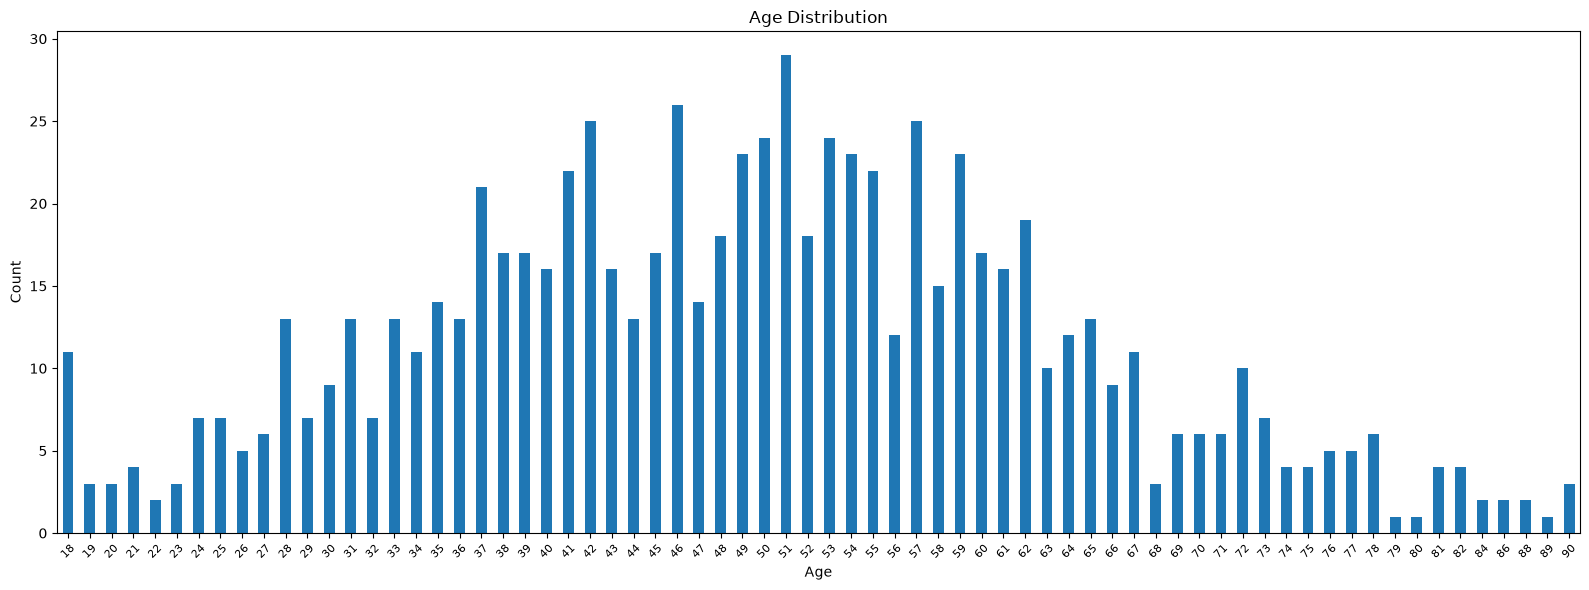

In [67]:
from src.visualization import plot_age_distribution, plot_age_counts

plot_age_distribution(df)
plot_age_counts(df)

3.2, Könsfördelning

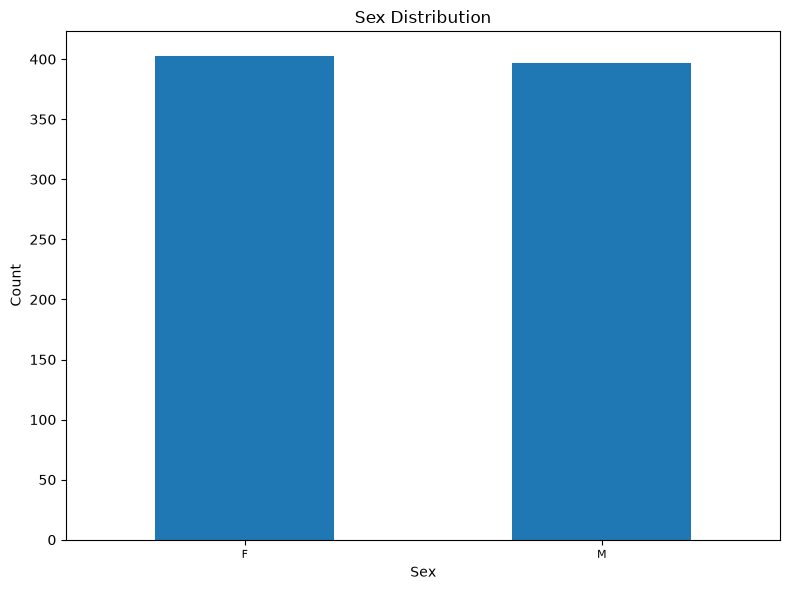

In [68]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_sex_distribution(df)

3.3 Längdfördelning

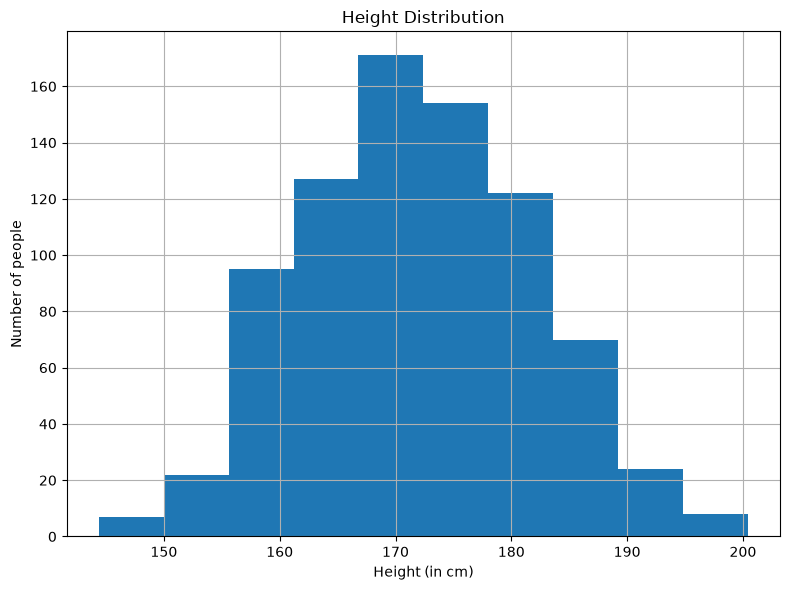

In [95]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_height_distribution(df)

Majoriteten av personerna verkar ha en längd mellan cirka 162 och 184 cm. Betydligt färre observationer förekommer runt 150 respektive 200 cm.

3.4, Viktfördelning

In [70]:
df["weight"].describe()

count    800.000000
mean      73.413000
std       13.685059
min       33.700000
25%       64.800000
50%       73.200000
75%       82.600000
max      114.400000
Name: weight, dtype: float64

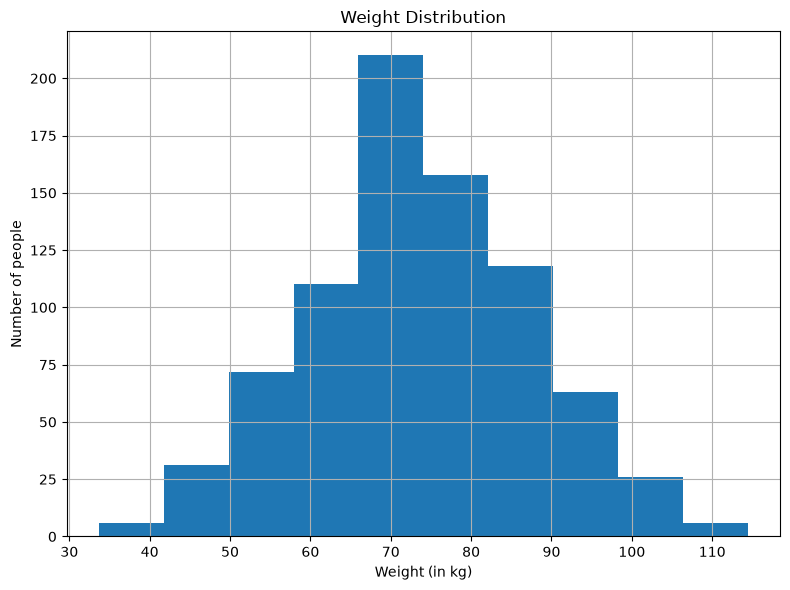

In [71]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_weight_distribution(df)

Den största koncentrationen av observationer ligger mellan cirka 66kg till 73kg. Drygt 200 personer återfinns inom detta viktintervall

3.5, Systolic_bp

In [72]:
df["systolic_bp"].describe()

count    800.000000
mean     149.178625
std       12.793360
min      106.800000
25%      140.900000
50%      149.400000
75%      157.600000
max      185.900000
Name: systolic_bp, dtype: float64

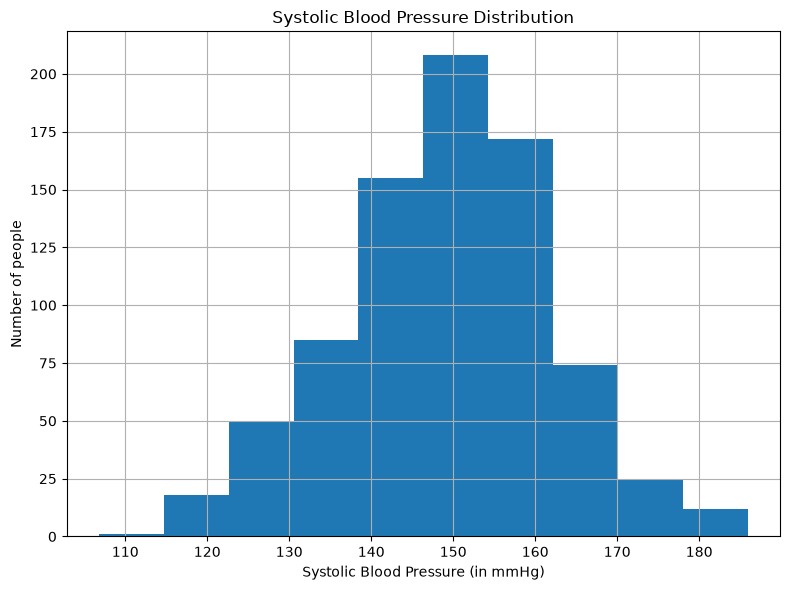

In [73]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_systolic_bp_distibution(df)

3.6, Kolesterol nivå

In [74]:
df["cholesterol"].describe()

count    800.000000
mean       4.929150
std        0.848413
min        2.500000
25%        4.327500
50%        4.970000
75%        5.482500
max        7.880000
Name: cholesterol, dtype: float64

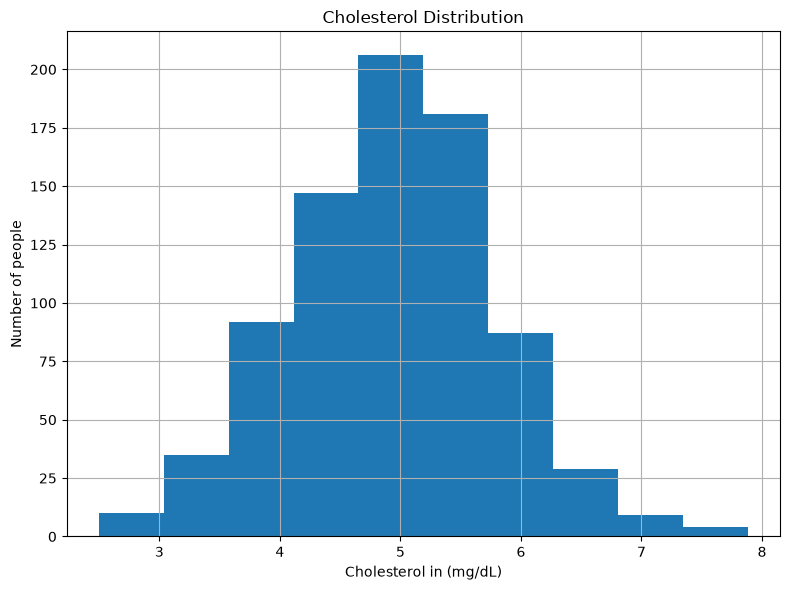

In [75]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_cholesterol_distribution(df)

3.7, Rökare

In [76]:
df["smoker"].describe()

count     800
unique      2
top        No
freq      587
Name: smoker, dtype: object

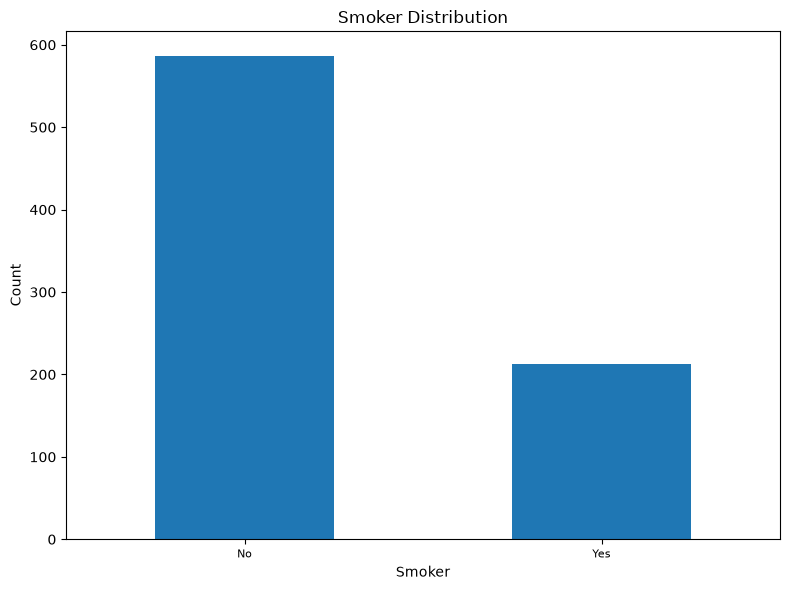

In [16]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_smoker_distribution(df)

3.8, Sjukdomar

In [77]:
df["disease"].value_counts()

disease
0    753
1     47
Name: count, dtype: int64

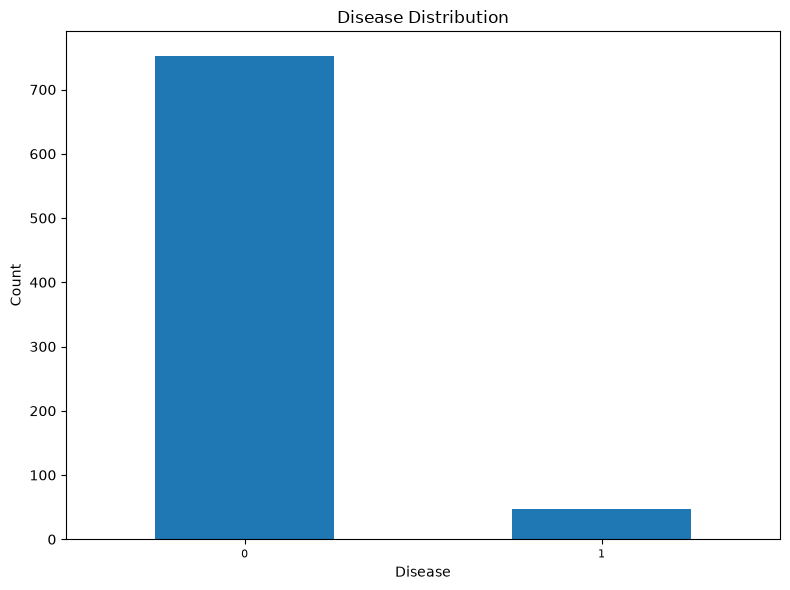

In [78]:
import importlib
import src.visualization

importlib.reload(src.visualization)

src.visualization.plot_disease_distribution(df)

Endast 47 av de 800 personerna (5,9 %) har registrerats med en sjukdom, medan resterande 753 personer (94,1 %) saknar registrerad sjukdom. Detta innebär en tydlig obalans mellan grupperna, vilket är viktigt att ta hänsyn till vid vidare analys.

## 4. Beskrivande statistik

I detta avsnitt sammanställs grundläggande statistiska mått för datasetets numeriska variabler. Medelvärde, median, minimi- och maximivärde används för att ge en tydligare bild av variablernas värden och spridning.

In [79]:
df[["age", "height", "weight", "systolic_bp", "cholesterol"]].agg(
    ["mean", "median", "std", "min", "max"]
)

,age,height,weight,systolic_bp,cholesterol
mean,49.426250,171.849250,73.413000,149.178625,4.929150
median,50.000000,171.350000,73.200000,149.400000,4.970000
std,14.501118,9.804259,13.685059,12.793360,0.848413
min,18.000000,144.400000,33.700000,106.800000,2.500000
max,90.000000,200.400000,114.400000,185.900000,7.880000


## 5. Simulering

I detta avsnitt genomförs en simulering med hjälp av NumPy. Syftet är att undersöka hur sjukdomsförekomsten kan se ut bland 1000 slumpmässigt genererade personer, baserat på sannolikheten i det ursprungliga datsetet

In [80]:
diesease_probability = df["disease"].mean()

print(diesease_probability)

0.05875


In [81]:
import importlib
import src.analysis

importlib.reload(src.analysis)

from src.analysis import simulate_disease_probability

In [82]:
simulated_proportion = simulate_disease_probability(df)
print(simulated_proportion)

0.056


In [83]:
actual_proportion = df["disease"].mean()
simulated_proportion = simulate_disease_probability(df)

print(f"Actual proportion: {actual_proportion: .2%}")
print(f"Simulated proportion: {simulated_proportion: .2%}")

Actual proportion:  5.88%
Simulated proportion:  5.60%


Simuleringen av 1 000 personer gav en sjukdomsförekomst på 5,6 %, jämfört med 5,88 % i det ursprungliga datasetet. Skillnaden är liten och visar att simuleringen ger ett resultat som ligger nära den faktiska sjukdomsförekomsten. Mindre variationer förväntas eftersom simuleringen bygger på slumpmässigt genererade värden.

In [84]:
import importlib
import src.analysis

importlib.reload(src.analysis)

from src.analysis import calculate_confidence_interval

In [85]:
lower, upper = src.analysis.calculate_confidence_interval(df, "systolic_bp")

print(f"Lower limit: {lower:.2f}")
print(f"Upper limit: {upper:.2f}")

Lower limit: 148.29
Upper limit: 150.07


Konfidensintervallet för det genomsnittliga systoliska blodtrycket är 148,29–150,07 mmHg med 95 % konfidens. Intervallet är relativt smalt, vilket innebär att skattningen av medelvärdet har hög precision.

## 6. Hypotesprövning

In [86]:
df["smoker"].unique()

<StringArray>
['No', 'Yes']
Length: 2, dtype: str

In [87]:
import importlib
import src.analysis

importlib.reload(src.analysis)

from src.analysis import test_smoker_blood_pressure

t_stat, p_value = test_smoker_blood_pressure(df)

print(f"Test statistic: {t_stat:.4f}")
print(f"P-value: {p_value:.4f}")

Test statistic: 0.4503
P-value: 0.3264


Hypotesprövningen genomfördes med Welch's t-test för att jämföra det genomsnittliga systoliska blodtrycket mellan rökare och icke-rökare.

Testet gav ett p-värde på 0,3264, vilket är högre än signifikansnivån 0,05. Därför kan nollhypotesen inte förkastas. Resultatet ger inte tillräckligt statistiskt stöd för att rökare har högre genomsnittligt systoliskt blodtryck än icke-rökare i detta dataset.

### Beräkning av medlevärde

Här skapar vi ett objekt av klassen HealthAnalyzer och använder det för att beräkna medelvärdet av personernas ålder i datasetet.

Syftet är att få en överblick över medelåldern bland personerna i undersökningen.

In [88]:
analyzer = HealthAnalyzer(df)

average_age = analyzer.calculate_average("age")

print(average_age)

49.42625


### Beräkning av median

Här beräknar vi medianåldern i datasetet. Medianen är det mittersta värdet när alla åldrar sorteras i storleksordning.

Detta ger oss ytterligare en bild av åldersfördelningen och gör det möjligt att jämföra medianen med medelvärdet.

In [89]:
median_age = analyzer.calculate_median("age")
print(median_age)

50.0


### Beräkning av standardavvikelse

Här beräknar vi standardavvikelsen för personernas ålder. Standardavvikelsen visar hur mycket åldrarna varierar kring medelvärdet.

Ett högre värde innebär större spridning i åldrarna, medan ett lägre värde innebär att åldrarna ligger närmare medelvärdet.

In [90]:
std_age = analyzer.calculate_standard_deviation("age")
print(std_age)

14.501117679508145


### Linjär regression för blodtryck

Här använder vi linjär regression för att undersöka sambandet mellan ålder och systoliskt blodtryck.

Med hjälp av NumPy beräknar vi en modell som beskriver hur blodtrycket förändras i förhållande till åldern. Metoden `np.linalg.lstsq` används för att hitta den linje som bäst passar datapunkterna.

Resultatet består av två värden: lutningen och interceptet, som används för att beräkna uppskattade blodtrycksvärden.

In [91]:
import importlib
import src.health_analyzer

importlib.reload(src.health_analyzer)
HealthAnalyzer = src.health_analyzer.HealthAnalyzer

test_analyzer = HealthAnalyzer(df)
print(test_analyzer.predict_blood_pressure())

[  0.5360256 122.6848897]


### Resultat från regressionen

Här skriver vi ut modellens lutning och intercept.

Lutningen visar hur mycket det uppskattade systoliska blodtrycket förändras för varje extra levnadsår. Interceptet är modellens beräknade startvärde när åldern är noll.

In [92]:
slope, intercept = test_analyzer.predict_blood_pressure()

print("Lutning:", slope)
print("Intercept:", intercept)

Lutning: 0.5360255996690334
Intercept: 122.68488970435848


### Uppdatering av analysklassen

Här laddar vi om modulen HealthAnalyzer för att säkerställa att de senaste ändringarna i koden används.

Därefter skapar vi ett nytt objekt som används i de kommande analyserna.

In [93]:
import importlib
import src.health_analyzer

importlib.reload(src.health_analyzer)
HealthAnalyzer = src.health_analyzer.HealthAnalyzer

test_analyzer = HealthAnalyzer(df)

### Uppskattning av blodtryck vid en viss ålder

Här använder vi vår linjära regressionsmodell för att uppskatta det systoliska blodtrycket hos en person som är 50 år gammal.

Genom att ange en ålder kan modellen beräkna ett uppskattat blodtryck baserat på sambandet i datasetet.

In [94]:
predicted_bp = test_analyzer.predict_for_age(50)


print("Förutsagt bloodtryck vid 50 års ålder", predicted_bp)

Förutsagt bloodtryck vid 50 års ålder 149.48616968781016


### Blodtryck i förhållande till ålder

I denna analys undersöker vi sambandet mellan personernas ålder och deras systoliska blodtryck. Med hjälp av linjär regression skapar vi en modell som uppskattar blodtrycket utifrån ålder.

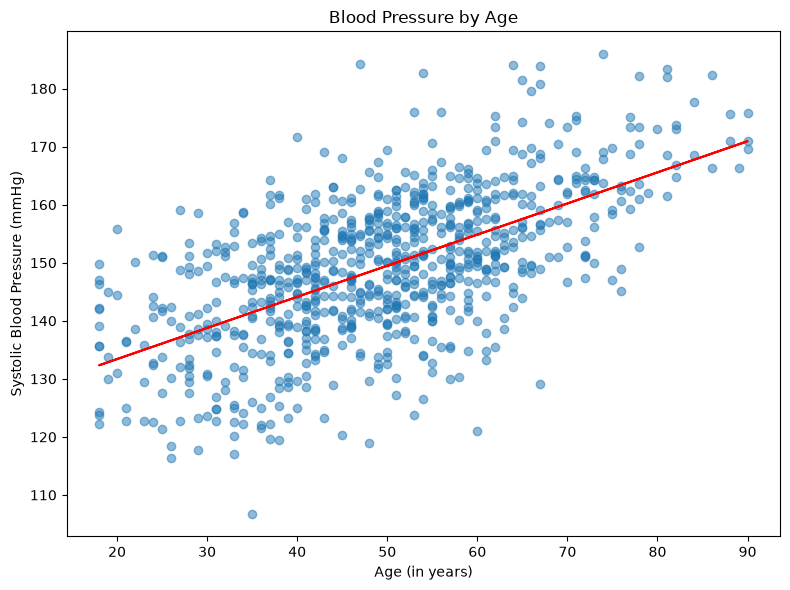

In [56]:
from src.visualization import plot_blood_pressure_by_age
plot_blood_pressure_by_age(df, test_analyzer)

Diagrammet visar personernas faktiska blodtryck som blå punkter och modellens uppskattade värden som en röd linje.

Resultatet visar ett positivt samband mellan ålder och systoliskt blodtryck. Det innebär att blodtrycket tenderar att öka med åldern i detta dataset. Sambandet innebär dock inte att ålder ensam avgör blodtrycket.